# Redes neuronales 8
---

Entrenar una red neuronal consiste en encontrar los valores de sus parámetros (pesos y umbrales) que hacen mínima una **función de pérdida**. Para ello necesitamos dos ingredientes:

1. **Una función de pérdida** $L(\theta)$ que mida cuánto se equivoca la red. Aquí $\theta$ representa el conjunto de todos los parámetros de la red.
2. **Un optimizador**, es decir, una regla que nos diga cómo modificar $\theta$ en cada paso para que $L(\theta)$ vaya bajando. Todos los optimizadores que veremos se basan en el **gradiente** $\nabla_\theta L$, que PyTorch calcula por nosotros con `loss.backward()`.

En esta clase repasamos las funciones de pérdida más habituales, estudiamos con detalle los optimizadores más usados, vemos cómo ir ajustando la tasa de aprendizaje durante el entrenamiento y, por último, cómo interpretar las gráficas de entrenamiento.

### Notación

A lo largo de la clase usaremos la siguiente notación:

| Símbolo | Significado |
|:-:|:--|
| $\theta_t$ | Parámetros de la red en el paso $t$ |
| $g_t = \nabla_\theta L(\theta_{t-1})$ | Gradiente de la pérdida en el paso $t$ (calculado sobre un *mini-batch*) |
| $\eta$ | Tasa de aprendizaje (*learning rate*) |
| $\epsilon$ | Constante muy pequeña (p. ej. $10^{-8}$) para evitar divisiones por cero |

Todas las operaciones con vectores (productos, cuadrados, raíces, divisiones) se aplican **elemento a elemento**, es decir, por separado a cada parámetro.

## 1. Funciones de pérdida

Existen varias funciones de pérdida (*loss*) que se usan comúnmente en redes. En todas ellas, $m$ es el número de muestras del *mini-batch*, $y_i$ la salida deseada para la muestra $i$ e $\hat{y}_i$ la salida que produce la red.

### Error cuadrático medio (MSE)

El *Mean Squared Error* es la media de los cuadrados de las diferencias entre la salida de la red y la salida deseada:

$$ \text{MSE} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}_i - y_i)^2 $$

Es la pérdida natural en problemas de **regresión** (predecir un valor numérico). Es la que usamos en las primeras clases para clasificar, pero para clasificación hay una opción mejor: la entropía cruzada.

### Entropía cruzada binaria

Cuando hay solo **dos clases**, la red tiene una única salida $\hat{y}_i \in (0, 1)$ (normalmente tras una sigmoide) que interpretamos como la probabilidad de que la muestra pertenezca a la clase $1$. La etiqueta $y_i$ vale $0$ o $1$. La *Binary Cross Entropy* es:

$$ \text{BCE} = -\frac{1}{m} \sum_{i=1}^{m} \Big[ y_i \log(\hat{y}_i) + (1-y_i) \log(1-\hat{y}_i) \Big] $$

Observa que, para cada muestra, solo uno de los dos sumandos es distinto de cero: si $y_i = 1$ la pérdida es $-\log(\hat{y}_i)$ y si $y_i = 0$ es $-\log(1-\hat{y}_i)$.

### Entropía cruzada categórica

Cuando hay $C$ clases, la red tiene $C$ salidas a las que se aplica la función **softmax**, que las convierte en probabilidades (positivas y que suman 1):

$$ \hat{y}_{c} = \text{softmax}(z)_c = \frac{e^{z_c}}{\sum_{k=1}^{C} e^{z_k}} $$

donde $z_1, \dots, z_C$ son las salidas de la última capa lineal (los *logits*). Con las etiquetas en formato *one-hot*, la *Categorical Cross Entropy* es:

$$ \text{CE} = -\frac{1}{m} \sum_{i=1}^{m} \sum_{c=1}^{C} y_{i,c} \log(\hat{y}_{i,c}) $$

Como en el vector *one-hot* solo hay un $1$, en la clase correcta $c^*$, la suma interior se reduce a un único término: la pérdida de cada muestra es simplemente $-\log(\hat{y}_{i,c^*})$, es decir, **menos el logaritmo de la probabilidad que la red asigna a la clase correcta**.

¿Por qué funciona tan bien? Fíjate en la forma de $-\log(p)$: si la red asigna probabilidad $p = 1$ a la clase correcta la pérdida es $0$; si asigna $p = 0.5$ la pérdida es $0.69$; y si asigna $p = 0.01$ la pérdida es $4.6$. Cuanto más segura está la red de una respuesta equivocada, más dura es la penalización, y su gradiente no se hace pequeño como ocurre con el MSE combinado con sigmoides o softmax.

### Funciones de pérdida en PyTorch

| Pérdida | PyTorch | Qué espera recibir |
|:--|:--|:--|
| MSE | `nn.MSELoss()` | Salidas de la red y valores deseados con la misma forma |
| Entropía cruzada binaria | `nn.BCEWithLogitsLoss()` | Salida **sin** sigmoide (la aplica internamente) y etiquetas $0$/$1$ en `float` |
| Entropía cruzada categórica | `nn.CrossEntropyLoss()` | Salidas **sin** softmax (la aplica internamente) y etiquetas como enteros $0, \dots, C-1$ |


## 2. Optimizadores

### 2.1. Descenso por el gradiente

El gradiente $\nabla_\theta L$ indica la dirección en la que la pérdida **crece** más rápidamente. La forma más simple de actualización consiste, por tanto, en dar un pequeño paso en la dirección contraria:

$$ \theta_t = \theta_{t-1} - \eta \, g_t $$

Según cuántas muestras usemos para calcular el gradiente $g_t$ hablamos de:

- **Descenso por el gradiente (*batch*)**: usa todas las muestras del conjunto de entrenamiento. El gradiente es exacto, pero cada paso es muy costoso.
- **Descenso estocástico (SGD)**: usa una única muestra elegida al azar. Cada paso es muy barato, pero el gradiente es muy ruidoso.
- **Descenso por *mini-batches***: usa un pequeño subconjunto aleatorio de muestras (por ejemplo, 32 o 128). Es el término medio y la opción que se usa en la práctica. Aunque sea un abuso del lenguaje, en el mundo de las redes neuronales a esto también se le llama SGD.

En PyTorch: `torch.optim.SGD(model.parameters(), lr=0.01)`.

#### Limitaciones

El descenso por el gradiente básico tiene varios problemas:

- **Elegir $\eta$ es delicado.** Si es muy pequeña el entrenamiento es lentísimo; si es muy grande la pérdida oscila o incluso diverge.
- **Valles alargados.** Cuando la función de pérdida es mucho más empinada en unas direcciones que en otras (algo muy habitual), el gradiente apunta sobre todo hacia las paredes del valle y no hacia el fondo. El resultado es un avance en **zigzag**: oscila mucho en la dirección empinada y avanza muy despacio en la dirección suave, que es justamente la que lleva al mínimo.
- **La misma tasa para todos los parámetros**, aunque unos reciban gradientes grandes y otros muy pequeños.
- **Mesetas y puntos de silla**, zonas donde el gradiente es casi cero y el avance se detiene.

Los optimizadores que veremos a continuación intentan resolver estos problemas. Los del apartado 2.2 añaden **inercia**; los del apartado 2.3 adaptan la **tasa de aprendizaje de cada parámetro**.

### 2.2. Métodos con momento

#### Momento

Imagina una bola rodando por la superficie de la función de pérdida. La bola no se mueve en la dirección exacta de la pendiente en cada instante: acumula **velocidad**. En las direcciones en las que la pendiente apunta siempre hacia el mismo lado, la velocidad crece y la bola acelera. En las direcciones en las que la pendiente cambia continuamente de sentido (el zigzag de antes), los empujones se cancelan entre sí y la oscilación se amortigua.

Para ello se introduce una variable de **velocidad** $v$, inicializada a $0$, que acumula los gradientes pasados:

$$
\begin{aligned}
v_t &= \mu \, v_{t-1} - \eta \, g_t \\
\theta_t &= \theta_{t-1} + v_t
\end{aligned}
$$

La constante $\mu \in [0, 1)$ es el **coeficiente de momento**. Se puede interpretar como un factor de fricción: con $\mu = 0$ recuperamos el descenso por el gradiente básico y, cuanto más cerca de $1$, más "memoria" tiene la velocidad. El valor típico es $\mu = 0.9$. Si desarrollamos la recurrencia vemos que la velocidad es una suma de todos los gradientes anteriores, con pesos que decrecen exponencialmente hacia el pasado:

$$ v_t = -\eta \left( g_t + \mu \, g_{t-1} + \mu^2 g_{t-2} + \mu^3 g_{t-3} + \dots \right) $$

En PyTorch: `torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)`.

#### Momento de Nesterov

El **momento de Nesterov** es una pequeña variación que suele funcionar algo mejor en la práctica y tiene mejores garantías teóricas de convergencia en funciones convexas. La idea es la siguiente: sabemos que, pase lo que pase, el término de momento $\mu v_{t-1}$ va a desplazarnos. Así que, en lugar de calcular el gradiente en la posición actual, lo calculamos en la posición a la que nos va a llevar el momento, es decir, **miramos hacia delante** antes de corregir el rumbo:

$$
\begin{aligned}
v_t &= \mu \, v_{t-1} - \eta \, \nabla_\theta L(\theta_{t-1} + \mu \, v_{t-1}) \\
\theta_t &= \theta_{t-1} + v_t
\end{aligned}
$$

<img src="imgs/nesterov.jpg">

En la figura, a la izquierda, el momento clásico suma el paso del momento (verde) y el paso del gradiente calculado en el punto actual (rojo). A la derecha, Nesterov calcula el gradiente en el punto al que nos lleva el momento. Si vamos a pasarnos de largo, ese gradiente "adelantado" lo detecta antes y frena.

En PyTorch: `torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, nesterov=True)`.

### 2.3. Métodos con tasa de aprendizaje adaptativa

Hasta ahora todos los parámetros se actualizaban con la misma tasa de aprendizaje $\eta$. Los siguientes métodos dan a **cada parámetro su propia tasa de aprendizaje efectiva**, que se ajusta automáticamente según el tamaño de los gradientes que ha recibido. Las animaciones siguientes muestran cómo se comportan los distintos optimizadores en dos superficies de pérdida: un valle alargado y un punto de silla.

<img src="imgs/opt1.gif" width="50%">
<img src="imgs/opt2.gif" width="50%">

#### Adagrad

Adagrad acumula, para cada parámetro, la **suma de los cuadrados de todos sus gradientes** pasados y divide el paso por su raíz cuadrada:

$$
\begin{aligned}
G_t &= G_{t-1} + g_t^2 \\
\theta_t &= \theta_{t-1} - \frac{\eta}{\sqrt{G_t} + \epsilon} \, g_t
\end{aligned}
$$

La variable $G$ (inicializada a $0$) tiene el mismo tamaño que $\theta$: hay un acumulador para cada parámetro. El efecto es que los parámetros que reciben **gradientes grandes** ven reducida su tasa de aprendizaje efectiva $\eta / \sqrt{G_t}$, mientras que los que reciben **gradientes pequeños o poco frecuentes** la mantienen alta. En el valle alargado, esto frena la dirección empinada y acelera la dirección suave, justo lo que necesitábamos. Curiosamente, la raíz cuadrada resulta ser muy importante: sin ella el algoritmo funciona mucho peor. El término $\epsilon$ (entre $10^{-4}$ y $10^{-8}$) solo evita la división por cero.

Su gran inconveniente es que $G_t$ **solo puede crecer**. Por tanto, la tasa de aprendizaje efectiva decrece continuamente y, en el entrenamiento de redes profundas, suele hacerse tan pequeña que la red deja de aprender demasiado pronto.

En PyTorch: `torch.optim.Adagrad(model.parameters(), lr=0.01)`.

#### RMSProp

RMSProp corrige el problema de Adagrad con un cambio muy sencillo: en lugar de acumular **todos** los gradientes al cuadrado, calcula una **media móvil exponencial**, de forma que los gradientes antiguos se van olvidando:

$$
\begin{aligned}
s_t &= \rho \, s_{t-1} + (1 - \rho) \, g_t^2 \\
\theta_t &= \theta_{t-1} - \frac{\eta}{\sqrt{s_t} + \epsilon} \, g_t
\end{aligned}
$$

El coeficiente de decaimiento $\rho$ suele valer $0.9$ o $0.99$. Ahora $s_t$ es una estimación del tamaño **reciente** de los gradientes de cada parámetro (de ahí el nombre: *Root Mean Square*), y la tasa de aprendizaje efectiva ya no decrece sin remedio.

En PyTorch: `torch.optim.RMSprop(model.parameters(), lr=0.001, alpha=0.99)` (PyTorch llama `alpha` a $\rho$).

#### Adam

Adam (*Adaptive Moment Estimation*) combina las dos ideas anteriores: el **momento** (una media móvil de los gradientes) y la **tasa adaptativa de RMSProp** (una media móvil de los gradientes al cuadrado):

$$
\begin{aligned}
m_t &= \beta_1 \, m_{t-1} + (1 - \beta_1) \, g_t & \text{(primer momento: media de los gradientes)} \\
v_t &= \beta_2 \, v_{t-1} + (1 - \beta_2) \, g_t^2 & \text{(segundo momento: media de sus cuadrados)}
\end{aligned}
$$

Hay un detalle importante. Como $m$ y $v$ se inicializan a $0$, durante los primeros pasos están **sesgados hacia cero** (por ejemplo, con $\beta_1 = 0.9$, en el primer paso $m_1 = 0.1 \, g_1$, diez veces más pequeño que el gradiente real). Adam corrige este sesgo dividiendo por un factor que tiende a $1$ a medida que avanza el entrenamiento:

$$
\hat{m}_t = \frac{m_t}{1 - \beta_1^t} \qquad \hat{v}_t = \frac{v_t}{1 - \beta_2^t}
$$

Y, finalmente, la actualización de los parámetros es:

$$ \theta_t = \theta_{t-1} - \eta \, \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon} $$

Los valores recomendados por sus autores, y que PyTorch usa por defecto, son $\beta_1 = 0.9$, $\beta_2 = 0.999$ y $\epsilon = 10^{-8}$. Adam es probablemente el optimizador más utilizado hoy en día: funciona razonablemente bien en casi cualquier problema sin necesidad de ajustar mucho sus hiperparámetros. Un buen valor de partida para la tasa de aprendizaje es $\eta = 10^{-3}$.

En PyTorch: `torch.optim.Adam(model.parameters(), lr=0.001, betas=(0.9, 0.999))`.

#### AdamW

Una técnica muy habitual para reducir el sobreajuste es el **decaimiento de pesos** (*weight decay*), que en cada paso empuja ligeramente los pesos hacia cero. En Adam, si este término se suma al gradiente, queda dividido por $\sqrt{\hat{v}_t}$ y su efecto se distorsiona. **AdamW** lo aplica por separado ("desacoplado"), directamente sobre los parámetros:

$$ \theta_t = \theta_{t-1} - \eta \left( \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon} + \lambda \, \theta_{t-1} \right) $$

donde $\lambda$ es el coeficiente de decaimiento de pesos. Es la variante que se usa, por ejemplo, para entrenar los grandes modelos de lenguaje.

En PyTorch: `torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)`.

### 2.4. Resumen

| Optimizador | Idea principal | Hiperparámetros típicos | PyTorch |
|:--|:--|:--|:--|
| SGD | Paso contrario al gradiente | $\eta$ | `optim.SGD` |
| Momento | Acumula una velocidad | $\eta$, $\mu = 0.9$ | `optim.SGD(..., momentum=0.9)` |
| Nesterov | Momento calculando el gradiente "adelantado" | $\eta$, $\mu = 0.9$ | `optim.SGD(..., momentum=0.9, nesterov=True)` |
| Adagrad | Tasa por parámetro según la suma de $g^2$ | $\eta$ | `optim.Adagrad` |
| RMSProp | Tasa por parámetro según la media móvil de $g^2$ | $\eta = 10^{-3}$, $\rho = 0.99$ | `optim.RMSprop` |
| Adam | Momento + RMSProp + corrección del sesgo | $\eta = 10^{-3}$, $\beta_1 = 0.9$, $\beta_2 = 0.999$ | `optim.Adam` |
| AdamW | Adam con *weight decay* desacoplado | Los de Adam y $\lambda = 0.01$ | `optim.AdamW` |

**Recomendación práctica:** empieza con **Adam** o **AdamW** y $\eta = 10^{-3}$. SGD con momento (o Nesterov) bien ajustado puede llegar a generalizar algo mejor en algunos problemas, por ejemplo en redes convolutivas para clasificación de imágenes, pero requiere más esfuerzo en la elección de la tasa de aprendizaje y de su programación (apartado 3).

### 2.5. Experimento: comparando optimizadores

Vamos a ver todo esto en acción. En lugar de entrenar una red, vamos a usar los optimizadores de PyTorch para buscar el mínimo de una función de solo dos parámetros, $\theta = (x, y)$, que podemos dibujar. Elegimos un **valle alargado**, mucho más empinado en la dirección $y$ que en la dirección $x$, con el mínimo en $(0, 0)$:

$$ L(x, y) = 0.05 \, x^2 + 2 \, y^2 $$

Todos los optimizadores parten del mismo punto, $(-4.5, 1.5)$, y dan $60$ pasos. La forma de usarlos es exactamente la misma que en el bucle de entrenamiento de una red: `zero_grad()`, `backward()` y `step()`.

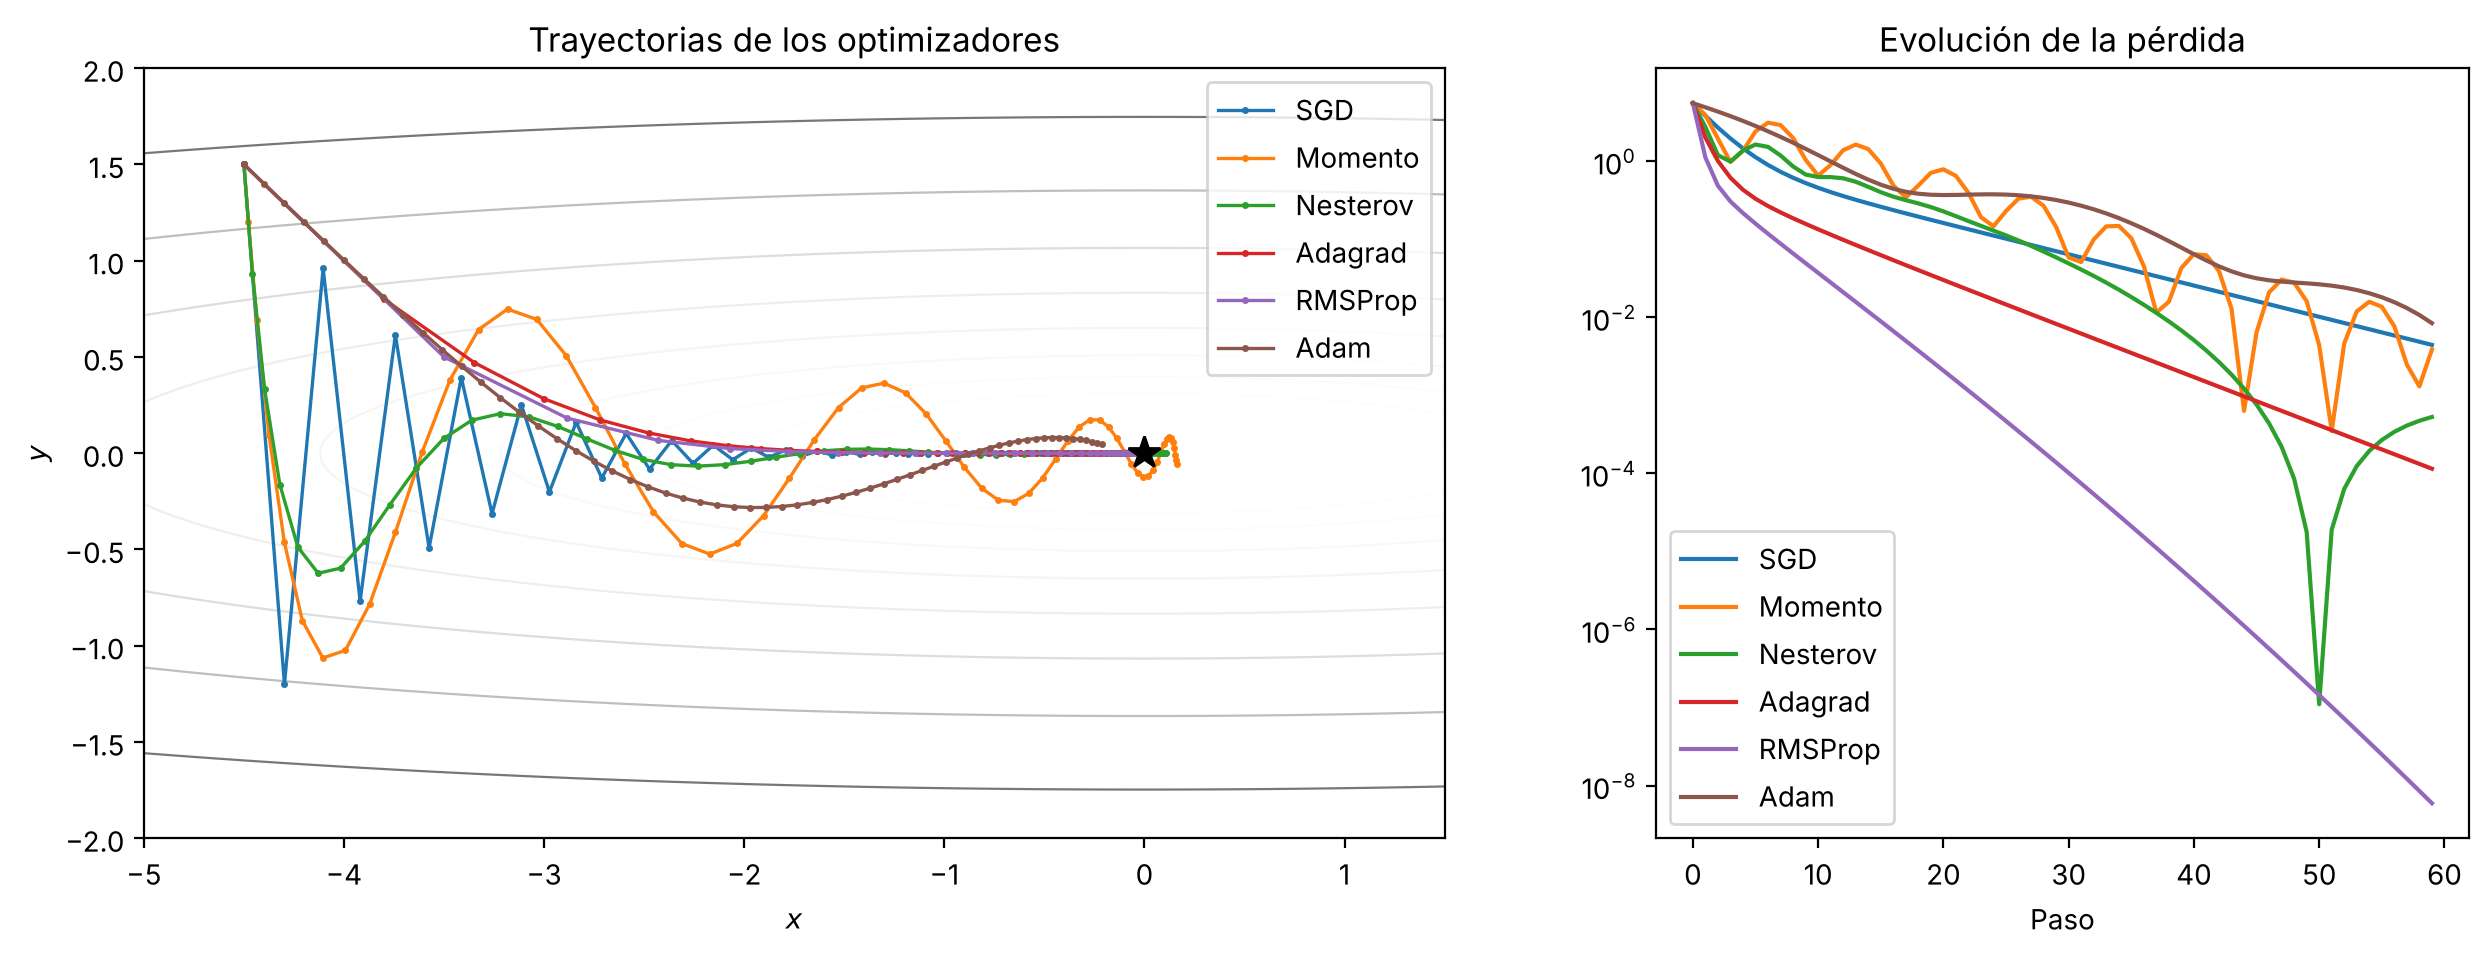

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def loss_fn(p):
    x, y = p
    return 0.05 * x**2 + 2 * y**2

optimizers = {
    'SGD':      lambda p: torch.optim.SGD([p], lr=0.45),
    'Momento':  lambda p: torch.optim.SGD([p], lr=0.05, momentum=0.9),
    'Nesterov': lambda p: torch.optim.SGD([p], lr=0.05, momentum=0.9, nesterov=True),
    'Adagrad':  lambda p: torch.optim.Adagrad([p], lr=0.7),
    'RMSProp':  lambda p: torch.optim.RMSprop([p], lr=0.1),
    'Adam':     lambda p: torch.optim.Adam([p], lr=0.1),
}

steps = 60
paths, losses = {}, {}

for name, make_optimizer in optimizers.items():
    p = torch.tensor([-4.5, 1.5], requires_grad=True)
    optimizer = make_optimizer(p)
    path, loss_values = [p.detach().clone()], []
    for _ in range(steps):
        loss = loss_fn(p)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        path.append(p.detach().clone())
        loss_values.append(loss.item())
    paths[name] = torch.stack(path).numpy()
    losses[name] = loss_values

# Trayectorias sobre las curvas de nivel
X, Y = np.meshgrid(np.linspace(-5, 1.5, 300), np.linspace(-2, 2, 300))
Z = 0.05 * X**2 + 2 * Y**2

fig, axs = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1.6, 1]})
axs[0].contour(X, Y, Z, levels=np.logspace(-2, 1, 15), cmap='Greys', linewidths=0.8)
for name, path in paths.items():
    axs[0].plot(path[:, 0], path[:, 1], '.-', markersize=3, linewidth=1.2, label=name)
axs[0].plot(0, 0, 'k*', markersize=12)
axs[0].set_title('Trayectorias de los optimizadores')
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].legend()

for name, values in losses.items():
    axs[1].plot(values, label=name)
axs[1].set_yscale('log')
axs[1].set_title('Evolución de la pérdida')
axs[1].set_xlabel('Paso')
axs[1].legend()

plt.show()

Fíjate en lo que muestra la gráfica:

- **SGD** oscila en zigzag en la dirección empinada ($y$) y avanza muy despacio en la dirección suave ($x$). No podemos subir más la tasa de aprendizaje para ir más rápido en $x$, porque entonces divergiría en $y$.
- **Momento** acumula velocidad en la dirección $x$ y llega mucho más lejos, aunque se pasa del mínimo y oscila alrededor de él antes de estabilizarse. **Nesterov** oscila menos porque "frena" antes.
- **Adagrad** y **RMSProp** ajustan la tasa de aprendizaje de cada parámetro: dan pasos de tamaño parecido en $x$ y en $y$ aunque los gradientes sean muy distintos, por lo que van prácticamente en línea recta hacia el mínimo.
- **Adam** también arranca en una dirección mucho más directa que SGD, pero, como incorpora momento, se pasa ligeramente del valle y oscila un poco antes de asentarse. En un problema tan sencillo y sin ruido no es el más rápido. Su ventaja aparece en las redes reales, donde los gradientes de cada *mini-batch* son ruidosos y la superficie de pérdida es mucho más complicada: ahí la combinación de momento y tasa adaptativa resulta muy robusta.

Los valores de las tasas de aprendizaje están elegidos para que cada optimizador se comporte razonablemente bien en este problema. Cámbialos y observa qué ocurre.

## 3. Programación de la tasa de aprendizaje

Al principio del entrenamiento estamos lejos del mínimo y nos interesa dar pasos grandes. Al final, cerca del mínimo, los pasos grandes nos hacen "rebotar" de un lado a otro sin llegar a asentarnos. Por eso suele ser buena idea **ir reduciendo la tasa de aprendizaje** a medida que avanza el entrenamiento. Esto se aplica tanto a SGD como a los optimizadores adaptativos. En las siguientes fórmulas, $\eta_0$ es la tasa de aprendizaje inicial y $t$ el número de época.

### Decaimiento por escalones

Se multiplica la tasa de aprendizaje por un factor $\gamma < 1$ cada $s$ épocas. Valores típicos son reducirla a la mitad cada 5 épocas, o multiplicarla por $0.1$ cada 20 épocas, aunque dependen mucho del problema y del modelo:

$$ \eta_t = \eta_0 \, \gamma^{\lfloor t / s \rfloor} $$

En PyTorch: `torch.optim.lr_scheduler.StepLR(optimizer, step_size=s, gamma=γ)`.

### Decaimiento exponencial

La tasa de aprendizaje se reduce de forma exponencial, donde $k$ es un hiperparámetro:

$$ \eta_t = \eta_0 \, e^{-k t} $$

En PyTorch: `torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=γ)`, que implementa $\eta_t = \eta_0 \gamma^t$. Es la misma fórmula con $\gamma = e^{-k}$.

### Decaimiento $1/t$

$$ \eta_t = \frac{\eta_0}{1 + k t} $$

En PyTorch no hay una clase específica, pero podemos definir cualquier programación con `LambdaLR`, que multiplica $\eta_0$ por la función que le pasemos: `torch.optim.lr_scheduler.LambdaLR(optimizer, lambda t: 1 / (1 + k * t))`.

### Decaimiento coseno

Es una de las programaciones más utilizadas actualmente. La tasa de aprendizaje baja suavemente desde $\eta_0$ hasta $\eta_{min}$ a lo largo de $T$ épocas siguiendo medio periodo de un coseno:

$$ \eta_t = \eta_{min} + \frac{1}{2} (\eta_0 - \eta_{min}) \left( 1 + \cos\left( \frac{\pi t}{T} \right) \right) $$

En PyTorch: `torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=T, eta_min=η_min)`.

### Reducir al estancarse

Una heurística muy utilizada en la práctica es entrenar con una tasa de aprendizaje fija mientras se observa el error de validación y, **cada vez que deja de mejorar** durante unas cuantas épocas, reducirla por un factor (por ejemplo, $0.5$ o $0.1$). Es la misma idea que el *early stopping* de la clase anterior, pero en lugar de parar, se reduce la tasa de aprendizaje.

En PyTorch: `torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)`.

Comparemos gráficamente cómo evoluciona la tasa de aprendizaje con cada una de ellas:

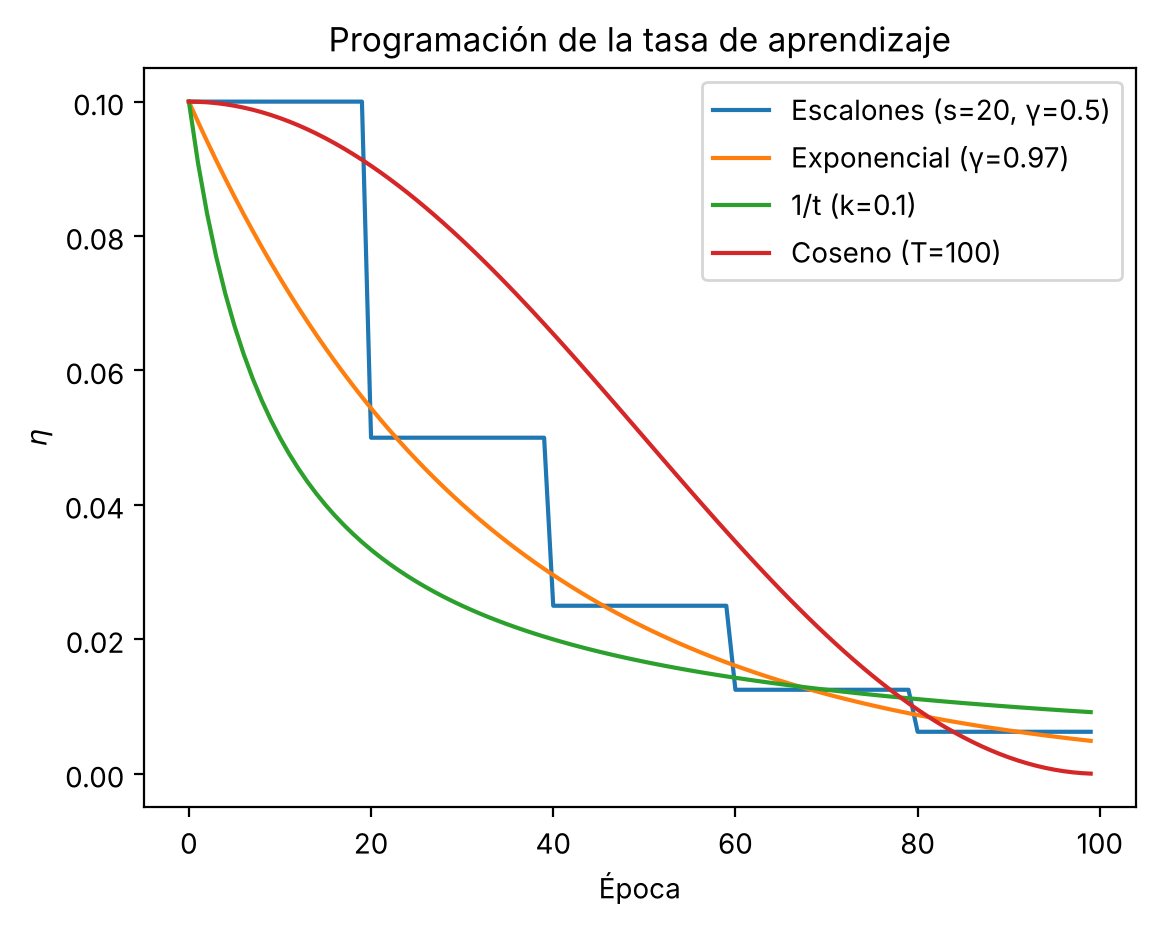

In [2]:
from torch.optim import lr_scheduler

epochs = 100
eta_0 = 0.1

schedulers = {
    'Escalones (s=20, γ=0.5)':   lambda opt: lr_scheduler.StepLR(opt, step_size=20, gamma=0.5),
    'Exponencial (γ=0.97)':      lambda opt: lr_scheduler.ExponentialLR(opt, gamma=0.97),
    '1/t (k=0.1)':               lambda opt: lr_scheduler.LambdaLR(opt, lambda t: 1 / (1 + 0.1 * t)),
    'Coseno (T=100)':            lambda opt: lr_scheduler.CosineAnnealingLR(opt, T_max=epochs),
}

for name, make_scheduler in schedulers.items():
    optimizer = torch.optim.SGD([torch.zeros(1, requires_grad=True)], lr=eta_0)
    scheduler = make_scheduler(optimizer)
    lrs = []
    for epoch in range(epochs):
        lrs.append(optimizer.param_groups[0]['lr'])
        optimizer.step()   # Aquí iría el entrenamiento de una época
        scheduler.step()   # Actualizamos la tasa de aprendizaje al final de cada época
    plt.plot(lrs, label=name)

plt.title('Programación de la tasa de aprendizaje')
plt.xlabel('Época')
plt.ylabel('$\\eta$')
plt.legend()
plt.show()

### Uso en el bucle de entrenamiento

Un programador de la tasa de aprendizaje (*scheduler*) se crea a partir del optimizador y se llama a su método `step()` **una vez al final de cada época**, después de los `optimizer.step()` de todos los *mini-batches*:

```python
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

for epoch in range(epochs):
    for x, y in train_loader:
        loss = loss_fn(model(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()      # Actualiza los pesos (en cada mini-batch)
    scheduler.step()          # Actualiza la tasa de aprendizaje (una vez por época)
```

La excepción es `ReduceLROnPlateau`, que necesita saber cómo va el error de validación, así que se lo pasamos: `scheduler.step(val_loss)`.

## 4. Seguimiento del entrenamiento

### Evolución de la pérdida

La primera cantidad que es útil seguir durante el entrenamiento es la **pérdida**, que se calcula sobre cada *mini-batch* durante la propagación hacia delante. Su gráfica nos dice mucho sobre si la tasa de aprendizaje es adecuada:

<img src="imgs/learningrates.jpg">

- **Tasa muy alta** (amarillo): los pasos son tan grandes que la pérdida se dispara. El entrenamiento diverge.
- **Tasa alta** (verde): la pérdida baja muy rápido al principio, pero se estanca en un valor alto. Los pasos son demasiado grandes para bajar al fondo del valle y la red "rebota" entre sus paredes. Programar la tasa de aprendizaje (apartado 3) suele resolverlo.
- **Tasa baja** (azul): la pérdida baja de forma casi lineal y muy despacio. Llegará, pero tardará mucho.
- **Tasa adecuada** (rojo): bajada rápida al principio y descenso suave hasta un valor bajo.

Como la pérdida se calcula sobre *mini-batches*, la curva real tiene bastante ruido. Si el ruido es muy grande, puede ser señal de que el tamaño del *mini-batch* es demasiado pequeño.

### Precisión en entrenamiento y validación

La segunda cantidad importante es la **precisión** (*accuracy*) sobre el conjunto de entrenamiento y sobre el de validación. La distancia entre ambas curvas indica cuánto **sobreajuste** (*overfitting*) hay en el modelo:

<img src="imgs/accuracies.jpg">

- Si la precisión de validación (azul) queda muy por debajo de la de entrenamiento (rojo) e incluso empieza a bajar, hay **mucho sobreajuste**: la red está memorizando el conjunto de entrenamiento. Conviene usar más datos (o *data augmentation*), aumentar la regularización (*dropout*, *weight decay*) o parar antes (*early stopping*).
- Si ambas curvas van muy juntas (verde), hay **poco sobreajuste**. Si además la precisión es baja, puede que el modelo sea demasiado pequeño para el problema y convenga aumentar su capacidad (más capas o más neuronas).

## Ejercicios

- En el experimento del apartado 2.5, sube la tasa de aprendizaje de SGD a $0.55$. ¿Qué ocurre? ¿Por qué? (Pista: calcula la derivada de $L$ respecto a $y$ y aplica la regla de actualización).


- En el mismo experimento, prueba distintos valores de $\mu$ para el momento ($0.5$, $0.9$, $0.99$) y describe cómo cambia la trayectoria.


- Comprueba que, con $\beta_1 = 0.9$, el factor de corrección del sesgo de Adam $1/(1-\beta_1^t)$ vale $10$ en el primer paso. ¿Cuánto vale tras $10$, $50$ y $100$ pasos?


- Vuelve a la red convolutiva de MNIST de la clase 6 y entrénala con SGD, SGD con momento, RMSProp y Adam. Dibuja en una misma gráfica la evolución del *accuracy* de validación de cada uno.


- Añade a ese entrenamiento un `CosineAnnealingLR` y un `ReduceLROnPlateau`. ¿Mejoran los resultados?